# Proyecto Parcial I: Predicción del rendimiento académico con aprendizaje automático
**Universidad de Guayaquil — Carrera de Ciencia de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 | **Grupo:** E | **Fecha:** 25 de noviembre de 2026

**Integrantes:**
- Granda Zambrano Cecilia Lorena
- Almeida Terry
- Campoverde María Fernanda
- Molina Sarco Juan
- Núñez Katherine

**Dataset:** Student Performance, Matemáticas (`student-mat.csv`), Cortez y Silva (2008).

**Preguntas:** (1) ¿Qué nota final obtendrá un estudiante? (2) ¿Aprobará o reprobará?

---
**Archivo independiente:** Parte4 Regresion Logistica

In [1]:
# Librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
import statsmodels.api as sm

SEED = 2026  # semilla del grupo (justificación en la Parte 2.5)

In [2]:
# Carga del dataset: funciona en Google Colab, en el PC, en GitHub Codespaces y en GitHub Actions
ARCHIVO = 'student-mat.csv'
rutas = [ARCHIVO, os.path.join('data', ARCHIVO)]
ruta = next((r for r in rutas if os.path.exists(r)), None)

if ruta is None:
    try:                      # solo existe en Google Colab
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Copie {ARCHIVO} en la misma carpeta del notebook.')
    print(f'Seleccione el archivo {ARCHIVO}')
    subido = files.upload()
    ruta = next(iter(subido))

df = pd.read_csv(ruta, sep=None, engine='python')  # detecta separador ',' o ';'
assert df.shape[1] == 33, 'El archivo no es el student-mat.csv esperado (33 columnas).'
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Preparación (necesaria para ejecutar esta parte sola)
El detalle y las justificaciones están en la Parte 2.

In [3]:
# Tipos de variables
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

In [4]:
# 2.1 Faltantes y duplicados en el dataset original
print('Faltantes originales:', df.isnull().sum().sum())
print('Filas duplicadas    :', df.duplicated().sum())

# Introducir 5 % de faltantes al azar (sobre una copia, para no alterar el EDA)
datos = df.copy()
rng = np.random.default_rng(SEED)
n_nan = int(round(0.05 * len(datos)))
for col in ['absences', 'studytime']:
    datos[col] = datos[col].astype(float)
    datos.loc[rng.choice(datos.index, size=n_nan, replace=False), col] = np.nan
print(datos[['absences', 'studytime']].isnull().sum())
print((datos[['absences', 'studytime']].isnull().mean() * 100).round(2))
print(df[['absences', 'studytime']].agg(['mean', 'median', 'skew']).round(2))

Faltantes originales: 0
Filas duplicadas    : 0
absences     20
studytime    20
dtype: int64
absences     5.06
studytime    5.06
dtype: float64
        absences  studytime
mean        5.71       2.04
median      4.00       2.00
skew        3.67       0.63


In [5]:
# Variable objetivo de clasificación (Parte 4.1)
datos['aprueba'] = (datos['G3'] >= 10).astype(int)

# 2.5 División 80/20. Se usa la MISMA partición para todos los modelos.
train, test = train_test_split(datos, test_size=0.20, random_state=SEED)
print(f'Entrenamiento: {len(train)} | Prueba: {len(test)}')

Entrenamiento: 316 | Prueba: 79


In [6]:
# 2.3 y 2.4 Preprocesamiento dentro de Pipeline + ColumnTransformer
feat_A = [c for c in df.columns if c != 'G3']                 # incluye G1 y G2
feat_B = [c for c in feat_A if c not in ['G1', 'G2']]         # sin G1 ni G2

def crear_pipeline(features, modelo):
    """Imputa, escala y codifica. Todo se ajusta solo con los datos de entrenamiento."""
    nums = [c for c in features if c in num_cols]
    cats = [c for c in features if c in cat_cols]
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), nums),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          # drop='first' evita la multicolinealidad perfecta entre dummies
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cats)
    ], sparse_threshold=0)
    return Pipeline([('preprocessor', prep), ('model', modelo)])

y_train, y_test = train['G3'], test['G3']

## Parte 4. Regresión logística
`aprueba` = 1 si G3 ≥ 10 y 0 en caso contrario (creada antes de la división). El modelo no usa G1, G2 ni G3.

In [7]:
# 4.2 y 4.3 Regresión logística sin G1, G2 ni G3 (feat_B no los contiene)
logit = crear_pipeline(feat_B, LogisticRegression(max_iter=1000)).fit(train[feat_B], train['aprueba'])
y_clf = test['aprueba']
proba = logit.predict_proba(test[feat_B])[:, 1]   # probabilidad de APROBAR
pred = (proba >= 0.5).astype(int)
print(f'Exactitud: {accuracy_score(y_clf, pred):.4f}')
print(f'Precisión: {precision_score(y_clf, pred):.4f}')
print(f'Recall   : {recall_score(y_clf, pred):.4f}')
print(f'AUC-ROC  : {roc_auc_score(y_clf, proba):.4f}')
print(f'Referencia (predecir siempre "aprueba"): exactitud = {y_clf.mean():.4f}')

Exactitud: 0.6962
Precisión: 0.7258
Recall   : 0.8654
AUC-ROC  : 0.7372
Referencia (predecir siempre "aprueba"): exactitud = 0.6582


Con umbral 0.5: exactitud 0.696, precisión 0.726 y recall 0.865 para la clase *aprueba*. La exactitud supera por poco a predecir siempre "aprueba" (0.658). El AUC de 0.737 indica una capacidad moderada para ordenar a los estudiantes.

### 4.4 Umbrales

,Umbral,Exactitud,Precisión (aprueba),Recall (aprueba),Precisión (riesgo),Recall (riesgo),En riesgo sin detectar,Falsas alarmas
0,0.3,0.709,0.710,0.942,0.700,0.259,20,3
1,0.5,0.696,0.726,0.865,0.588,0.370,17,7
2,0.7,0.620,0.806,0.558,0.465,0.741,7,23


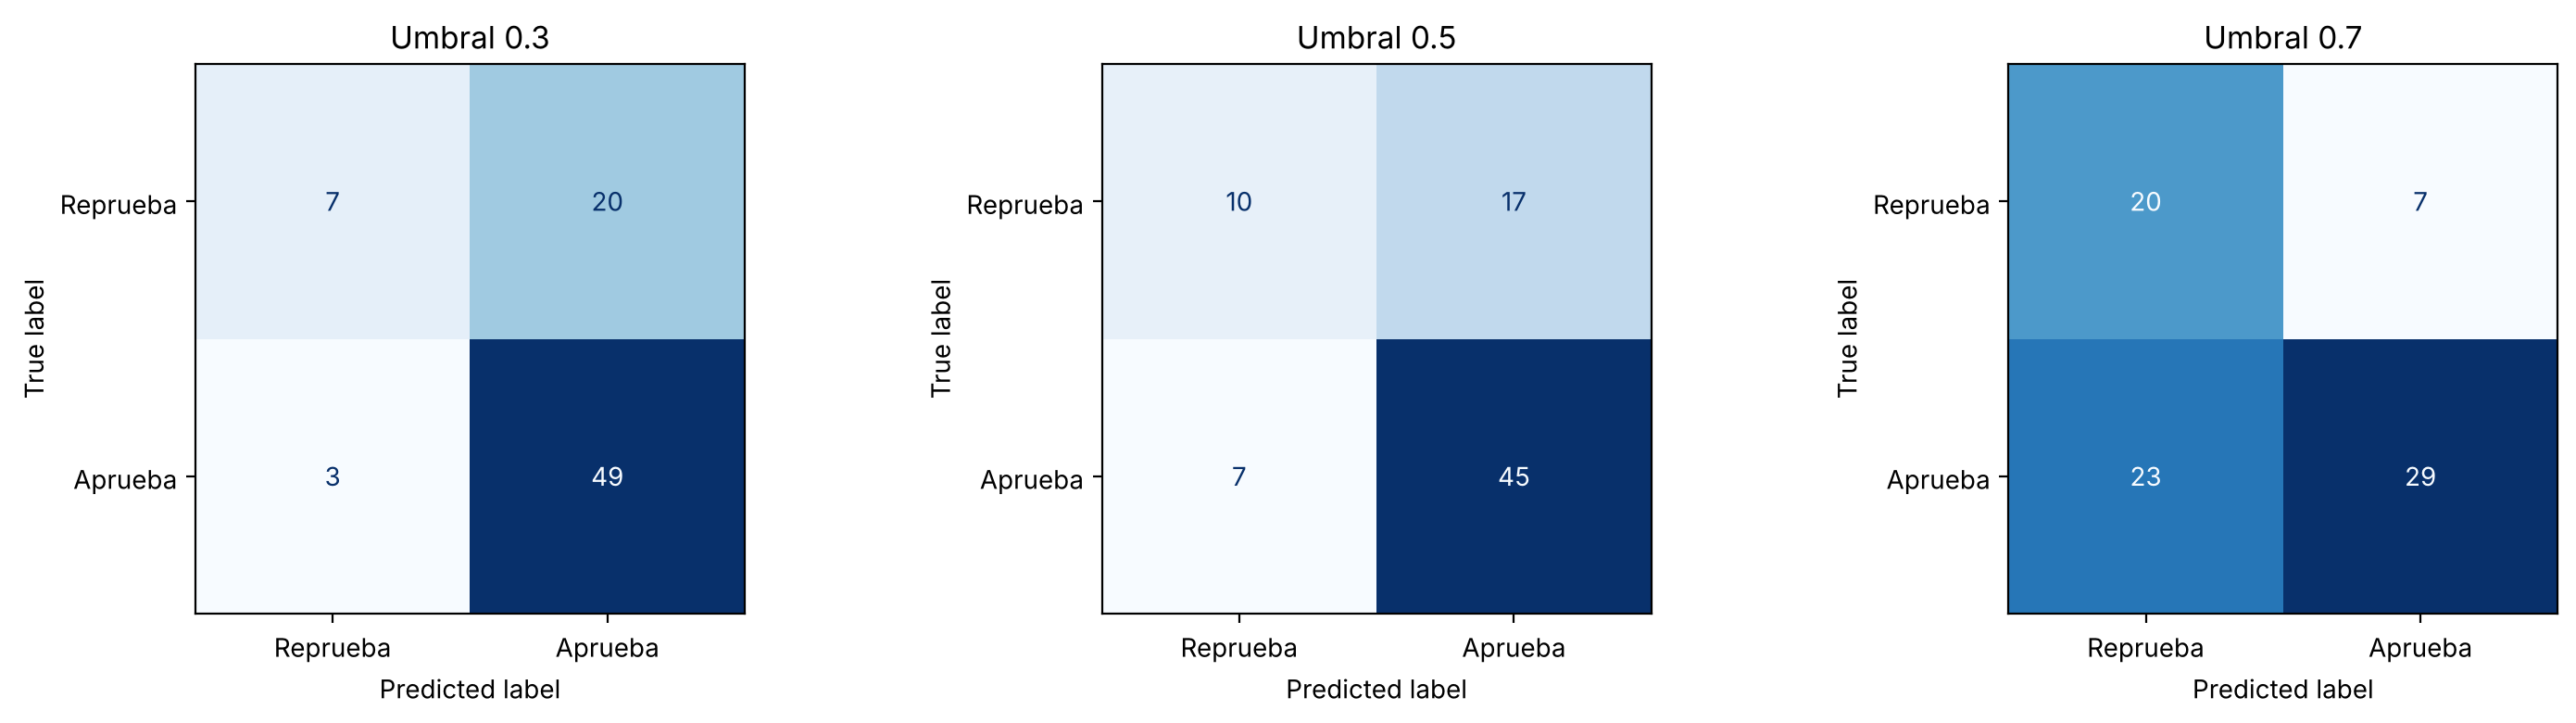

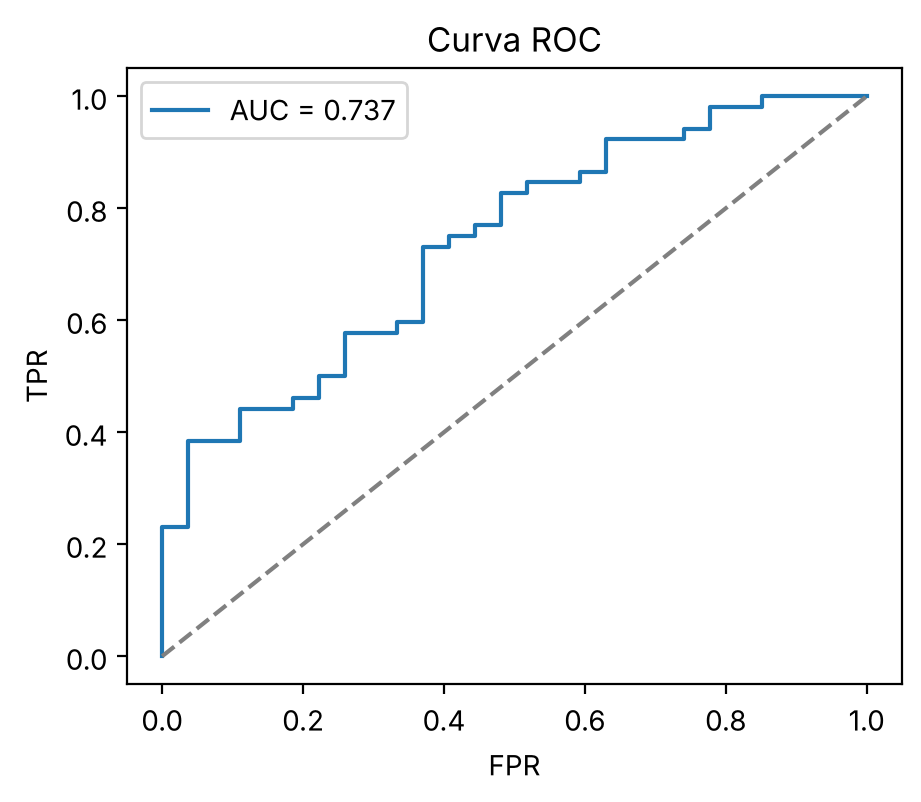

In [8]:
# 4.4 Umbrales. El umbral se aplica a P(aprobar): si P >= umbral se predice "aprueba".
# Para el apoyo interesa la clase "en riesgo" (reprueba = 0), por eso se reportan ambas clases.
umbrales = [0.3, 0.5, 0.7]
filas = []
for u in umbrales:
    p = (proba >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_clf, p, labels=[0, 1]).ravel()
    filas.append({'Umbral': u, 'Exactitud': accuracy_score(y_clf, p),
                  'Precisión (aprueba)': precision_score(y_clf, p, zero_division=0),
                  'Recall (aprueba)': recall_score(y_clf, p),
                  'Precisión (riesgo)': precision_score(y_clf, p, pos_label=0, zero_division=0),
                  'Recall (riesgo)': recall_score(y_clf, p, pos_label=0),
                  'En riesgo sin detectar': fp, 'Falsas alarmas': fn})
tabla_umb = pd.DataFrame(filas).round(3)
display(tabla_umb)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, u in zip(ax, umbrales):
    ConfusionMatrixDisplay(confusion_matrix(y_clf, (proba >= u).astype(int)),
                           display_labels=['Reprueba', 'Aprueba']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(f'Umbral {u}')
plt.tight_layout(); plt.show()

fpr, tpr, _ = roc_curve(y_clf, proba)
plt.figure(figsize=(5, 4)); plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_clf, proba):.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray'); plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('Curva ROC'); plt.legend(); plt.show()

### 4.5 Pregunta crítica: ¿qué umbral elegir?
El modelo estima la probabilidad de **aprobar**. Un estudiante se marca en riesgo si esa probabilidad es **menor** que el umbral. Por eso, subir el umbral detecta a más estudiantes en riesgo.

Entre los tres elegimos **0.7**:

| Umbral | Recall de estudiantes en riesgo | En riesgo sin detectar (de 27) | Falsas alarmas |
|---|---|---|---|
| 0.3 | 0.259 | 20 | 3 |
| 0.5 | 0.370 | 17 | 7 |
| **0.7** | **0.741** | **7** | **23** |

**Costo:** la exactitud baja a 0.620 (menor que la referencia de 0.658), la precisión de la clase en riesgo baja a 0.465 y se marcan 43 de 79 estudiantes, de los cuales 23 habrían aprobado. Esto exige más tutores y tiempo, y puede generar estigma. Además, **ni siquiera 0.7 cumple el objetivo de no dejar a ninguno sin apoyo**, porque faltan 7. Se necesita complementar con el criterio docente y permitir que los estudiantes pidan ayuda.

En la práctica, el umbral debería fijarse con validación en entrenamiento. Aquí los tres valores se comparan en prueba porque la guía lo solicita, así que el resultado puede ser optimista.

## Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)* (pp. 5–12). EUROSIS.

> **Pendiente del grupo:** agregar en APA 7 las fuentes que realmente hayan consultado en la biblioteca de la Universidad.

## Declaración de uso de inteligencia artificial
Se utilizó Claude (Anthropic) para revisar el notebook frente a la guía, corregir y completar el código, ejecutarlo y redactar un borrador de las interpretaciones y conclusiones. El grupo debe revisar el contenido, redactar las respuestas con sus propias palabras y poder explicar cada línea en la defensa.